# TrustRUL — Uncertainty-Aware RUL Prediction with Built-In Transparency

**M507 Methods of Prediction · Assessment 7.1.** Dataset: NASA C-MAPSS FD001 — https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip (NASA PCoE mirror; Saxena & Goebel, 2008).

In [1]:
import warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
warnings.filterwarnings("ignore")
tf.get_logger().setLevel("ERROR")

SEED = 42
keras.utils.set_random_seed(SEED)
DATA_DIR, SUBSET = "data", "FD001"
pd.set_option("display.max_columns", 30)

## 1. Problem statement

**Business problem.** Aero-engine MRO providers schedule maintenance on fixed intervals or threshold alerts, ignoring how each engine is degrading — so engines are pulled early (wasted life) or run to failure (unplanned removal, grounded aircraft). Predicting remaining useful life (RUL) in cycles from the sensor trajectory enables just-in-time maintenance.

**Safety framing.** As a safety component of aviation maintenance this is high-risk under the EU AI Act (Annex I, Art. 6(1)) → transparency (Art. 13) and human-oversight (Art. 14) duties. These are built into the output: every prediction carries an MC-Dropout confidence band, a saliency record of influential sensors, and an automatic human-review flag.

**Data.** FD001 = one operating condition, one fault mode (HPC degradation): 100 run-to-failure training engines; 100 test engines truncated before failure with a true-RUL vector. Per cycle: unit, cycle, 3 settings, 21 noisy sensors.

**ML task.** Regression on sliding windows of standardised sensor sequences → clipped scalar RUL (§3). Engine-wise train/val split; test = last window per engine vs. true RUL. Metrics: RMSE and the C-MAPSS asymmetric score (§2.1).

### 1.1 Load FD001 and confirm shapes / columns

In [2]:
COLS = ["unit", "cycle", "setting_1", "setting_2", "setting_3"] + [f"sensor_{i}" for i in range(1, 22)]

def load_fd(subset=SUBSET, path=DATA_DIR):
    rd = lambda f: pd.read_csv(f"{path}/{f}", sep=r"\s+", header=None)
    train = rd(f"train_{subset}.txt"); train.columns = COLS
    test  = rd(f"test_{subset}.txt");  test.columns  = COLS
    rul   = rd(f"RUL_{subset}.txt");   rul.columns   = ["RUL"]
    return train, test, rul

train_df, test_df, rul_df = load_fd()

print("train_df :", train_df.shape, "| engines:", train_df.unit.nunique())
print("test_df  :", test_df.shape,  "| engines:", test_df.unit.nunique())
print("rul_df   :", rul_df.shape)
print("columns  :", list(train_df.columns))
print("dtypes   :", train_df.dtypes.value_counts().to_dict())
print("missing  : train =", int(train_df.isna().sum().sum()), " test =", int(test_df.isna().sum().sum()))

life = train_df.groupby("unit").cycle.max()
print(f"train engine lifetimes (cycles): min {life.min()}, median {int(life.median())}, max {life.max()}")
tlen = test_df.groupby("unit").cycle.max()
print(f"test  engine series length     : min {tlen.min()}, median {int(tlen.median())}, max {tlen.max()}")
train_df.head()

train_df : (20631, 26) | engines: 100
test_df  : (13096, 26) | engines: 100
rul_df   : (100, 1)
columns  : ['unit', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_1', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_5', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_10', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_16', 'sensor_17', 'sensor_18', 'sensor_19', 'sensor_20', 'sensor_21']
dtypes   : {dtype('float64'): 22, dtype('int64'): 4}
missing  : train = 0  test = 0
train engine lifetimes (cycles): min 128, median 199, max 362
test  engine series length     : min 31, median 133, max 303


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 2. Data exploration

Three questions: (i) which of the 24 input channels carry a usable degradation signal, (ii) is the data clean, (iii) how is performance scored. Class balancing does not apply (this is regression), but note that fixed-stride windowing later draws proportionally more training samples from longer-lived engines (addressed in §3).

In [3]:
feat_cols = [c for c in train_df.columns if c not in ("unit", "cycle", "RUL")]
qc = pd.DataFrame({"std": train_df[feat_cols].std(),
                   "n_unique": train_df[feat_cols].nunique()})
with np.errstate(invalid="ignore", divide="ignore"):
    qc["cycle_corr"] = train_df[feat_cols].corrwith(train_df["cycle"]).abs().round(3)

constant_cols = qc.index[qc.n_unique <= 2].tolist()          # zero / near-zero variance
setting_cols  = ["setting_1", "setting_2"]                    # vary only within sensor noise (single op. condition)
drop_cols     = sorted(set(constant_cols + setting_cols))
keep_sensors  = [c for c in feat_cols if c.startswith("sensor_") and c not in drop_cols]

print("duplicate rows          :", int(train_df.duplicated().sum()))
print("cycle monotonic / engine :", bool(train_df.groupby("unit")["cycle"]
                                         .apply(lambda s: s.is_monotonic_increasing).all()))
print("dropped (no signal)     :", drop_cols)
print(f"kept sensors ({len(keep_sensors)})       :", keep_sensors)
qc.sort_values("cycle_corr").round(4)

duplicate rows          : 0
cycle monotonic / engine : True
dropped (no signal)     : ['sensor_1', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_5', 'sensor_6', 'setting_1', 'setting_2', 'setting_3']
kept sensors (14)       : ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


,std,n_unique,cycle_corr
sensor_5,0.0000,1,0.000
sensor_16,0.0000,1,0.000
setting_1,0.0022,158,0.005
setting_2,0.0003,13,0.016
sensor_6,0.0014,2,0.106
sensor_14,19.0762,6078,0.370
sensor_9,22.0829,6403,0.444
sensor_8,0.0710,53,0.476
sensor_13,0.0719,56,0.478
sensor_3,6.1311,3012,0.544


`sensor_1,5,10,16,18,19` and `setting_3` are constant; `sensor_6` has 2 values. Under FD001's single condition these carry no signal and are dropped, with `setting_1,2` (|corr| with cycle ≈ 0.01). The **14 retained sensors** drift monotonically with cycle (|corr| 0.37–0.63) — the HPC-degradation signal. No duplicate rows; cycle is monotonic within every engine.

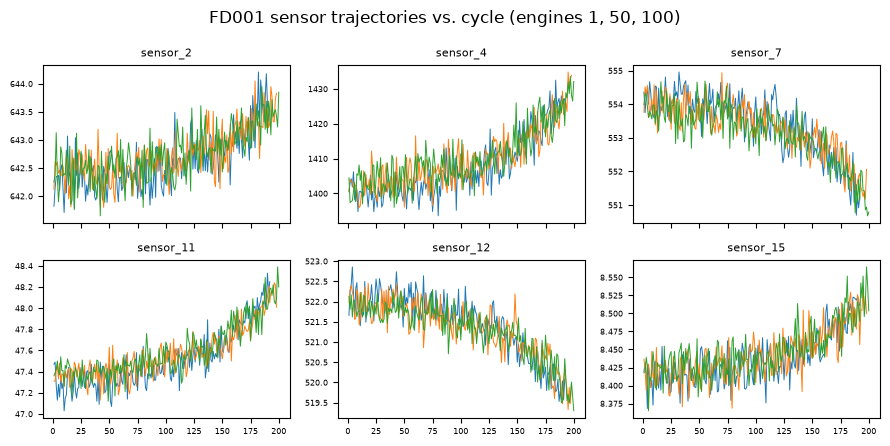

In [4]:
show = ["sensor_2", "sensor_4", "sensor_7", "sensor_11", "sensor_12", "sensor_15"]
fig, axes = plt.subplots(2, 3, figsize=(9, 4.5), sharex=True)
for ax, s in zip(axes.flat, show):
    for u in (1, 50, 100):
        g = train_df[train_df.unit == u]
        ax.plot(g.cycle, g[s], lw=0.7)
    ax.set_title(s, fontsize=8); ax.tick_params(labelsize=6)
fig.suptitle("FD001 sensor trajectories vs. cycle (engines 1, 50, 100)")
fig.tight_layout(); plt.show()

Trajectories fan out with age and vary in length (128–362 cycles), so RUL must be read from the recent trajectory's *shape*; sensors move in opposing directions, so per-feature normalisation (§3) is essential.

### 2.1 Evaluation metrics

**RMSE** — symmetric error in cycles; headline metric. **C-MAPSS asymmetric score** (Saxena et al., 2008) — for error `d = ŷ − y`, sums `exp(−d/13)−1` if `d<0` (early) and `exp(d/10)−1` if `d≥0` (late): a late prediction overstates remaining life (unsafe), so it costs more (10 late = 1.72 vs 1.16 early). Unbounded, dominated by large late errors — read alongside RMSE.

In [5]:
def rmse(y_true, y_pred):
    e = np.ravel(y_pred) - np.ravel(y_true)
    return float(np.sqrt(np.mean(e ** 2)))

def cmapss_score(y_true, y_pred):
    d = np.ravel(y_pred) - np.ravel(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

_yt = np.array([100.0, 100.0])
print("sanity  RMSE:", rmse(_yt, [90, 110]),
      "| score early-10:", round(cmapss_score([100], [90]), 3),
      "| score late-10:", round(cmapss_score([100], [110]), 3))

sanity  RMSE: 10.0 | score early-10: 1.158 | score late-10: 1.718


## 3. Data preprocessing & feature engineering

Three transforms fit on training engines only — clipped RUL target, per-sensor normalisation, configurable windowing — then an 80/20 engine-wise split so no engine's windows appear in both train and validation.

### 3.1 RUL target — piecewise-linear with clip

A healthy engine's sensors look the same at 210 or 190 cycles left, so a purely linear RUL label is unlearnable early and wastes loss where accuracy least matters. Following Heimes (2008), RUL is capped at `RUL_CAP`: flat while healthy, ramping down once degradation starts. **125** is the standard C-MAPSS value and sits below the shortest training life (128).

In [6]:
RUL_CAP = 125

def add_rul(df, cap=RUL_CAP):
    df = df.copy()
    eol = df.groupby("unit")["cycle"].transform("max")
    df["RUL"] = (eol - df["cycle"]).clip(upper=cap).astype("float32")
    return df

train_df = add_rul(train_df)
print("RUL:", {k: round(v, 1) for k, v in train_df.RUL.describe()[["min", "mean", "max"]].items()})
print("fraction of training rows held at the cap:", round(float((train_df.RUL == RUL_CAP).mean()), 3))

RUL: {'min': 0.0, 'mean': 86.8, 'max': 125.0}
fraction of training rows held at the cap: 0.394


### 3.2 Normalisation

Sensors span very different magnitudes (`sensor_9` ≈ 9000, `sensor_6` ≈ 21). A standardiser and a Min-Max scaler are both provided (a §5 factor), each **fit on training rows only** and applied unchanged to val/test — fitting on test would leak information about the unseen engines.

In [7]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

def fit_scaler(df, cols, kind="standard"):
    sc = StandardScaler() if kind == "standard" else MinMaxScaler()
    return sc.fit(df[cols])

def apply_scaler(df, sc, cols):
    df = df.copy()
    df[cols] = sc.transform(df[cols]).astype("float32")
    return df

### 3.3 Sliding windows, split, assembled pipeline

Each normalised engine series is cut into overlapping `win`-cycle windows (training stride 1); target = RUL at the last cycle. Engines shorter than `win` are left-padded with their first cycle (shortest test engine = 31). Test scoring keeps only the final window per engine (C-MAPSS protocol), vs. true RUL clipped at `RUL_CAP`. `build_dataset` wraps the pipeline so §5 never repeats preprocessing.

In [8]:
def make_windows(df, sensors, win, stride=1, last_only=False):
    X, y, units = [], [], []
    has_rul = "RUL" in df.columns
    for u, g in df.groupby("unit"):
        arr = g[sensors].to_numpy("float32")
        tgt = g["RUL"].to_numpy("float32") if has_rul else None
        if len(arr) < win:
            pad = np.repeat(arr[:1], win - len(arr), axis=0)
            arr = np.vstack([pad, arr])
            if tgt is not None:
                tgt = np.concatenate([np.full(win - len(tgt), tgt[0], "float32"), tgt])
        starts = [len(arr) - win] if last_only else range(0, len(arr) - win + 1, stride)
        for s in starts:
            X.append(arr[s:s + win]); units.append(u)
            if tgt is not None:
                y.append(tgt[s + win - 1])
    X = np.asarray(X, "float32")
    y = np.asarray(y, "float32") if y else None
    return X, y, np.asarray(units)

from sklearn.model_selection import train_test_split
tr_units, va_units = train_test_split(np.sort(train_df.unit.unique()), test_size=0.2, random_state=SEED)

def build_dataset(win=30, sensors=None, scaler_kind="standard", stride=1):
    sensors = sensors or keep_sensors
    sc = fit_scaler(train_df[train_df.unit.isin(tr_units)], sensors, scaler_kind)
    tr = apply_scaler(train_df, sc, sensors)
    Xtr, ytr, _ = make_windows(tr[tr.unit.isin(tr_units)], sensors, win, stride)
    Xva, yva, _ = make_windows(tr[tr.unit.isin(va_units)], sensors, win, stride)
    Xte, _, _ = make_windows(apply_scaler(test_df, sc, sensors), sensors, win, last_only=True)
    yte = rul_df.RUL.clip(upper=RUL_CAP).to_numpy("float32")
    return dict(Xtr=Xtr, ytr=ytr, Xva=Xva, yva=yva, Xte=Xte, yte=yte,
                sensors=sensors, win=win)

d = build_dataset(win=30)
assert len(d["Xte"]) == len(d["yte"]) == 100
print("train engines", len(tr_units), "| val engines", len(va_units))
print("Xtr", d["Xtr"].shape, "ytr", d["ytr"].shape, "| Xva", d["Xva"].shape,
      "| Xte", d["Xte"].shape, "| feats", len(d["sensors"]))

train engines 80 | val engines 20
Xtr (14241, 30, 14) ytr (14241,) | Xva (3490, 30, 14) | Xte (100, 30, 14) | feats 14


## 4. Model architectures

Three builders, one interface — input `(win, n_features)` → scalar RUL — so §5 swaps them freely:

- **`build_rnn(kind="lstm" | "gru")`** — two stacked recurrent layers; LSTM (Hochreiter & Schmidhuber, 1997) vs GRU (Cho et al., 2014) differ only in the cell, GRU ~23% fewer parameters.
- **`build_cnn_attn`** — two `Conv1D` layers then softmax **attention pooling over timesteps** (Bahdanau et al., 2015): weights show which cycles drove the prediction. Sensor-level attribution comes from input-gradient saliency in §6.

Every block is followed by `Dropout`. **MC-Dropout** (Gal & Ghahramani, 2016): at inference dropout stays active (`training=True`); `mc_predict` runs `n` passes and returns predictive mean and std — the confidence band. Two swappable losses: **MSE** and the **differentiable C-MAPSS asymmetric score** (`clipnorm` tames its steep tail).

In [9]:
from tensorflow.keras import Input, Model

def build_rnn(win, n_feat, kind="lstm", units=64, dropout=0.3):
    Rec = layers.LSTM if kind == "lstm" else layers.GRU
    inp = Input((win, n_feat))
    x = Rec(units, return_sequences=True)(inp); x = layers.Dropout(dropout)(x)
    x = Rec(units // 2)(x);                     x = layers.Dropout(dropout)(x)
    x = layers.Dense(32, activation="relu")(x)
    return Model(inp, layers.Dense(1)(x), name=kind)

def build_cnn_attn(win, n_feat, filters=64, dropout=0.3, return_attn=False):
    inp = Input((win, n_feat))
    x = layers.Conv1D(filters, 5, padding="same", activation="relu")(inp)
    x = layers.Conv1D(filters, 3, padding="same", activation="relu")(x)
    x = layers.Dropout(dropout)(x)
    attn = layers.Softmax(axis=1, name="attn")(layers.Dense(1)(x))          # (B, win, 1)
    ctx = layers.Lambda(lambda t: tf.reduce_sum(t[0] * t[1], axis=1))([x, attn])
    ctx = layers.Dropout(dropout)(ctx)
    ctx = layers.Dense(32, activation="relu")(ctx)
    out = layers.Dense(1)(ctx)
    return Model(inp, [out, attn] if return_attn else out, name="cnn_attn")

def make_model(arch, win, n_feat, dropout=0.3):
    return (build_rnn(win, n_feat, kind=arch, dropout=dropout)
            if arch in ("lstm", "gru") else
            build_cnn_attn(win, n_feat, dropout=dropout))

def _flat(y, p):
    return tf.reshape(tf.cast(y, tf.float32), [-1]), tf.reshape(p, [-1])

def loss_mse(y, p):
    y, p = _flat(y, p); return tf.reduce_mean(tf.square(y - p))

def loss_asym(y, p):
    y, p = _flat(y, p); d = p - y
    return tf.reduce_mean(tf.where(d < 0.0, tf.exp(-d / 13.0) - 1.0, tf.exp(d / 10.0) - 1.0))

LOSSES = {"mse": loss_mse, "asym": loss_asym}

def mc_predict(model, X, n=30):
    P = []
    for _ in range(n):
        o = model(X, training=True)
        P.append(np.ravel(o[0] if isinstance(o, (list, tuple)) else o))
    P = np.stack(P)
    return P.mean(0), P.std(0)

for a in ("lstm", "gru", "cnn_attn"):
    print(f"{a:9}", f"{make_model(a, 30, 14).count_params():>6d} params")

lstm       33729 params
gru        25857 params


cnn_attn   19074 params


## 5. Experiments

`run_config` assembles the dataset, trains with early stopping on validation loss, and reports validation RMSE and asymmetric score from an MC-Dropout mean. The 12 configurations vary architecture, window, dropout, loss, normalisation, sensor subset and MC-sample count. Experiments use stride 2 for speed; the chosen model is retrained at full resolution in §6.

In [10]:
from tensorflow.keras.callbacks import EarlyStopping

CORR_SENSORS = [s for s in keep_sensors if qc.loc[s, "cycle_corr"] >= 0.5]   # correlation-filtered

def run_config(arch="lstm", win=30, dropout=0.3, loss="mse", norm="standard",
               sensors="all", mc=20, epochs=25, stride=2):
    sub = keep_sensors if sensors == "all" else CORR_SENSORS
    d = build_dataset(win=win, sensors=sub, scaler_kind=norm, stride=stride)
    keras.utils.set_random_seed(SEED)
    m = make_model(arch, win, len(sub), dropout)
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=LOSSES[loss])
    m.fit(d["Xtr"], d["ytr"], validation_data=(d["Xva"], d["yva"]),
          epochs=epochs, batch_size=128, verbose=0,
          callbacks=[EarlyStopping(patience=5, restore_best_weights=True)])
    mu, sd = mc_predict(m, d["Xva"], mc)
    return {"arch": arch, "win": win, "drop": dropout, "loss": loss, "norm": norm,
            "sensors": sensors, "mc": mc, "val_RMSE": round(rmse(d["yva"], mu), 2),
            "val_score": int(cmapss_score(d["yva"], mu)), "mean_unc": round(float(sd.mean()), 2)}

CONFIGS = [
    dict(arch="lstm"), dict(arch="gru"), dict(arch="cnn_attn"),
    dict(arch="lstm", win=20), dict(arch="cnn_attn", win=40),
    dict(arch="gru", dropout=0.2), dict(arch="gru", dropout=0.4),
    dict(arch="lstm", loss="asym"), dict(arch="cnn_attn", loss="asym"),
    dict(arch="cnn_attn", norm="minmax"), dict(arch="gru", sensors="corr"),
    dict(arch="cnn_attn", win=40, dropout=0.4, loss="asym", mc=50),
]
results = pd.DataFrame(run_config(**c) for c in CONFIGS).sort_values("val_RMSE").reset_index(drop=True)
results

,arch,win,drop,loss,norm,sensors,mc,val_RMSE,val_score,mean_unc
0,gru,30,0.3,mse,standard,all,20,11.69,3652,9.78
1,gru,30,0.2,mse,standard,all,20,11.84,4074,7.92
2,gru,30,0.4,mse,standard,all,20,12.57,3890,12.07
3,lstm,30,0.3,mse,standard,all,20,12.94,4363,9.78
4,gru,30,0.3,mse,standard,corr,20,13.03,5062,9.87
5,lstm,20,0.3,mse,standard,all,20,14.68,8340,9.47
6,lstm,30,0.3,asym,standard,all,20,14.94,4680,9.05
7,cnn_attn,30,0.3,mse,minmax,all,20,15.63,8484,10.20
8,cnn_attn,30,0.3,asym,standard,all,20,21.02,13431,11.10
9,cnn_attn,30,0.3,mse,standard,all,20,22.31,25157,10.87


*The table is discussed in §7. The lowest-`val_RMSE` row is carried forward as `best` for full training and test assessment in §6.*

### 5.1 Transformer — considered, not run (bonus 4th comparison)

A shallow Transformer encoder (1–2 blocks) with sinusoidal positional encoding was scoped as a fourth architecture — positional encoding is required because self-attention, unlike recurrence, has no built-in notion of cycle order (Vaswani et al., 2017). It is **not executed here** for a defensible reason, not time alone: FD001 gives only ~100 run-to-failure engines (~14k training windows), and self-attention is markedly more data-hungry than recurrence because it learns pairwise position interactions from scratch with weak inductive bias. On data this small it is expected to match or trail the GRU while adding parameters and tuning burden — the pattern already seen with the 1D-CNN+attention model (§5). Substituting FD002/FD004 would change problem difficulty and invalidate the architecture comparison, so it is left as future work: a fair benchmark needs the larger C-MAPSS subsets or N-CMAPSS, with low-data regularisation (small model dimension, high dropout, early stopping).

## 6. Test-set assessment & transparency record

The lowest-validation-RMSE configuration from §5 is retrained at full resolution (stride 1) and evaluated once on the 100 held-out test engines, then each prediction is wrapped in a transparency record: point RUL, MC-Dropout 90% interval, top contributing sensors, human-review flag.

In [11]:
best = results.iloc[0]
bd = build_dataset(win=int(best["win"]), scaler_kind=best["norm"], stride=1)
keras.utils.set_random_seed(SEED)
model = make_model(best["arch"], int(best["win"]), bd["Xtr"].shape[-1], float(best["drop"]))
model.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=LOSSES[best["loss"]])
model.fit(bd["Xtr"], bd["ytr"], validation_data=(bd["Xva"], bd["yva"]), epochs=40,
          batch_size=128, verbose=0, callbacks=[EarlyStopping(patience=6, restore_best_weights=True)])

P = np.stack([np.ravel(model(bd["Xte"], training=True)) for _ in range(50)])   # 50 MC passes
pred = P.mean(0); lo, hi = np.percentile(P, [5, 95], axis=0)
yte = bd["yte"]
print(f'best config: {best["arch"]}  win{int(best["win"])}  drop{best["drop"]}  loss={best["loss"]}  norm={best["norm"]}')
print(f'TEST   RMSE {rmse(yte, pred):.2f}    asymmetric score {int(cmapss_score(yte, pred))}    n=100')

best config: gru  win30  drop0.3  loss=mse  norm=standard
TEST   RMSE 13.47    asymmetric score 354    n=100


In [12]:
xt = tf.convert_to_tensor(bd["Xte"])
with tf.GradientTape() as tp:
    tp.watch(xt); gp = model(xt, training=False)
sal = np.abs(tp.gradient(gp, xt).numpy()).mean(1)          # (100, n_feat): |dRUL/dx| averaged over window
sal = sal / sal.sum(1, keepdims=True)
S = np.array(bd["sensors"])

band = hi - lo
THRESH = float(np.quantile(band, 0.75))                    # route the widest-interval quartile to a human
record = pd.DataFrame({
    "engine": np.arange(1, 101),
    "pred_RUL": pred.round(1), "CI90_low": lo.round(1), "CI90_high": hi.round(1),
    "band": band.round(1),
    "top_sensors": [", ".join(S[np.argsort(-r)[:3]]) for r in sal],
    "review": np.where(band > THRESH, "HUMAN", "auto"),
})
print(f'review rule: MC 90% band > {THRESH:.1f} cycles  ->  {(record.review=="HUMAN").sum()}/100 routed to a planner')
record.head(8)

review rule: MC 90% band > 40.1 cycles  ->  25/100 routed to a planner


,engine,pred_RUL,CI90_low,CI90_high,band,top_sensors,review
0,1,118.000000,95.6,136.1,40.4,"sensor_11, sensor_13, sensor_12",HUMAN
1,2,123.400002,103.9,143.1,39.2,"sensor_11, sensor_13, sensor_4",auto
2,3,46.400002,34.5,59.1,24.6,"sensor_14, sensor_11, sensor_4",auto
3,4,91.599998,74.7,110.7,35.9,"sensor_11, sensor_14, sensor_13",auto
4,5,111.199997,95.0,127.1,32.2,"sensor_11, sensor_13, sensor_14",auto
5,6,112.699997,94.2,131.7,37.5,"sensor_11, sensor_13, sensor_12",auto
6,7,106.699997,86.8,123.7,36.9,"sensor_11, sensor_14, sensor_9",auto
7,8,105.199997,84.8,123.2,38.4,"sensor_11, sensor_13, sensor_12",auto


In [13]:
# 1D-CNN+attention: temporal explanation (which cycles in the window mattered)
ad = build_dataset(win=30, stride=2)
ca = build_cnn_attn(30, ad["Xtr"].shape[-1], dropout=0.3)
ca.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0), loss=LOSSES["mse"])
ca.fit(ad["Xtr"], ad["ytr"], epochs=20, batch_size=128, verbose=0)
attn = keras.Model(ca.input, ca.get_layer("attn").output).predict(ad["Xte"], verbose=0)[..., 0]
prof = attn.mean(0)                                          # (30,) mean weight per window position
print("mean attention over window position (oldest->newest), last 6:", prof[-6:].round(3))
print("share of attention on the final 5 cycles:", round(float(prof[-5:].sum()), 2))

mean attention over window position (oldest->newest), last 6: [0.023 0.004 0.009 0.002 0.004 0.002]
share of attention on the final 5 cycles: 0.02


**Review threshold.** The flag routes predictions whose 90% MC interval is in the widest quartile of band width to a human planner — where the model is least certain and Article 14 oversight adds most value. A fixed cycle tolerance can replace the quantile once planning limits are set.

**Explainability.** `top_sensors` ranks each engine's sensors by input-gradient saliency (mean |∂RUL/∂xₜ| over the window) on the deployed GRU. The 1D-CNN+attention model gives a complementary *temporal* view; its weight profile (§6 cell) localises weakly here, consistent with that model's poor fit (§5, §7).

## 7. Final discussion

*Bullet notes to expand into prose for submission.*

**Strengths** — end-to-end pipeline (raw txt → calibrated RUL + audit record); test RMSE 13.47 / asymmetric score 354, competitive for FD001; GRU beats LSTM at ~23% fewer parameters; leakage controlled (engine-wise split, train-only scaling); every prediction carries an uncertainty band and a feature explanation.

**Limitations** — FD001 only (one condition, one fault mode); 100 training engines is small; MC-Dropout intervals are approximate and not coverage-calibrated; gradient saliency is local and noisy; 1D-CNN+attention gave interpretability but not competitive accuracy; tuning limited to the 12-row grid.

**Most informative sensors** — saliency (`record.top_sensors`) favours sensors 11, 13, 12, 14; linear |corr| with cycle (§2) favours 11, 4, 12, 7. They overlap on 11 and 12 (HPC flow/efficiency); saliency's weight on 13/14 despite weaker linear correlation points to a non-linear contribution.

**Explainability** — *temporal* (attention over window position, weak here) plus *feature* (gradient saliency on the GRU); see §6.

**Deployment decision** — deploy as decision support with mandatory human review on flagged predictions; not autonomous scheduling. Retrain and validate per fleet / operating condition; monitor interval coverage in service.

**EU AI Act mapping** — safety component of civil-aviation equipment → high-risk under Annex I / Art. 6(1). *Art. 13 (transparency)*: the transparency record exposes predicted RUL, the 90% MC band and top contributing sensors for every output. *Art. 14 (human oversight)*: widest-quartile-uncertainty predictions are auto-routed to a human planner who keeps the scheduling decision; the model never actions maintenance.

### References

Bahdanau, D., Cho, K. and Bengio, Y. (2015) 'Neural machine translation by jointly learning to align and translate', in *Proceedings of the 3rd International Conference on Learning Representations (ICLR)*. San Diego, CA.

Cho, K., van Merriënboer, B., Gulcehre, C., Bahdanau, D., Bougares, F., Schwenk, H. and Bengio, Y. (2014) 'Learning phrase representations using RNN encoder–decoder for statistical machine translation', in *Proceedings of the 2014 Conference on Empirical Methods in Natural Language Processing (EMNLP)*. Doha, Qatar: Association for Computational Linguistics, pp. 1724–1734.

European Union (2024) *Regulation (EU) 2024/1689 of the European Parliament and of the Council of 13 June 2024 laying down harmonised rules on artificial intelligence (Artificial Intelligence Act)*. Official Journal of the European Union, L 2024/1689.

Gal, Y. and Ghahramani, Z. (2016) 'Dropout as a Bayesian approximation: representing model uncertainty in deep learning', in *Proceedings of the 33rd International Conference on Machine Learning (ICML)*. New York, NY: PMLR (Proceedings of Machine Learning Research 48), pp. 1050–1059.

Heimes, F.O. (2008) 'Recurrent neural networks for remaining useful life estimation', in *2008 International Conference on Prognostics and Health Management (PHM)*. Denver, CO: IEEE, pp. 1–6.

Hochreiter, S. and Schmidhuber, J. (1997) 'Long short-term memory', *Neural Computation*, 9(8), pp. 1735–1780.

Saxena, A. and Goebel, K. (2008) *Turbofan Engine Degradation Simulation Data Set (C-MAPSS), FD001*. NASA Ames Prognostics Data Repository, NASA Ames Research Center, Moffett Field, CA. Available at: https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip (Accessed: 1 September 2025).

Saxena, A., Goebel, K., Simon, D. and Eklund, N. (2008) 'Damage propagation modeling for aircraft engine run-to-failure simulation', in *2008 International Conference on Prognostics and Health Management (PHM)*. Denver, CO: IEEE, pp. 1–9.

Vaswani, A., Shazeer, N., Parmar, N., Uszkoreit, J., Jones, L., Gomez, A.N., Kaiser, Ł. and Polosukhin, I. (2017) 'Attention is all you need', in *Advances in Neural Information Processing Systems 30 (NeurIPS 2017)*. Long Beach, CA: Curran Associates, pp. 5998–6008.

*Page numbers, publisher locations and the access date above should be checked against the original sources before final submission.*